# 5. Modeling

This notebook trains and compares several classification models to predict the **probability of default (PD)** of each client.

The main objectives are:

- Prepare the data without data leakage
- Compare an interpretable model (Logistic Regression) with tree-based models (Random Forest and XGBoost)
- Evaluate the models with the metrics used in credit risk
- Check if the predicted probabilities are reliable (calibration)
- Save the final model for the credit policy analysis

In [1]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.calibration import calibration_curve
from xgboost import XGBClassifier

In [2]:
# Load the dataset
df = pd.read_csv("../data/HMEQ_features.csv")
df.shape

(5960, 26)

## 5.1 Train / test split

The data is split into a training set (80%) and a test set (20%). The split is **stratified**, so both sets keep the same proportion of defaults (~20%).

The test set is not used until the final evaluation. All the decisions (model selection, threshold) are made using only the training data.

In [3]:
# Separate the features and the target variable
X = df.drop(columns=['BAD'])
y = df['BAD']

categorical_cols = ['REASON', 'JOB']
numeric_cols = [col for col in X.columns if col not in categorical_cols]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f"Train: {X_train.shape[0]:,} rows | default rate: {y_train.mean():.2%}")
print(f"Test:  {X_test.shape[0]:,} rows | default rate: {y_test.mean():.2%}")

Train: 4,768 rows | default rate: 19.95%
Test:  1,192 rows | default rate: 19.97%


## 5.2 Preprocessing pipeline

The missing values are imputed with the **median** inside a `Pipeline`. This way, the median is calculated only with the training data of each fold, and no information from the test set is used during training (data leakage).

- **Numerical variables:** median imputation. For Logistic Regression they are also standardized, because this model is sensitive to the scale of the variables. Tree-based models do not need it.
- **Categorical variables:** One-Hot Encoding.

The `_missing` indicators created in the cleaning stage keep the information of which values were originally missing.

In [4]:
# Function to create the preprocessing step
def make_preprocessor(scale_numeric):
    numeric_steps = [('imputer', SimpleImputer(strategy='median'))]

    if scale_numeric:
        numeric_steps.append(('scaler', StandardScaler()))

    return ColumnTransformer([
        ('num', Pipeline(numeric_steps), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

## 5.3 Evaluation metrics

The dataset is imbalanced (80% good loans / 20% defaults). A model that predicts "no default" for everyone would have 80% accuracy and would be useless, so **accuracy is not used**.

Instead, the models are evaluated with:

- **ROC-AUC:** probability that the model gives a higher risk score to a random defaulter than to a random good client. 0.5 = random, 1 = perfect.
- **Gini:** `2 × AUC − 1`. It is the same information as the AUC, but it is the standard metric used by banks to measure the discriminatory power of a scorecard.
- **PR-AUC (Average Precision):** focuses on the defaulters (the minority class). The baseline is the default rate (~0.20).
- **KS statistic:** maximum separation between the cumulative distributions of good and bad clients. Also very common in credit scoring.
- **Brier score:** average squared error of the predicted probabilities. Lower is better. It measures if the probabilities are reliable, not only if the ranking is good.

In credit risk the probability itself matters, because it is used to calculate the expected loss and to decide which loans to approve.

## 5.4 Model comparison with cross-validation

In [5]:
# Define the models
models = {
    'Logistic Regression': Pipeline([
        ('preprocessor', make_preprocessor(scale_numeric=True)),
        ('model', LogisticRegression(max_iter=2000))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', make_preprocessor(scale_numeric=False)),
        ('model', RandomForestClassifier(n_estimators=500, min_samples_leaf=2, n_jobs=-1, random_state=42))
    ]),
    'XGBoost': Pipeline([
        ('preprocessor', make_preprocessor(scale_numeric=False)),
        ('model', XGBClassifier(
            n_estimators=400, learning_rate=0.05, max_depth=4,
            subsample=0.8, colsample_bytree=0.8,
            eval_metric='logloss', random_state=42
        ))
    ])
}

Each model is evaluated with **5-fold stratified cross-validation** on the training set. The training data is divided into 5 parts: the model is trained with 4 and evaluated with the remaining one, 5 times. The average gives a more stable estimate than a single split.

In [6]:
# Compare the models with 5-fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train,
        cv=cv,
        scoring=['roc_auc', 'average_precision', 'neg_brier_score']
    )

    cv_results.append({
        'model': name,
        'ROC-AUC': scores['test_roc_auc'].mean(),
        'ROC-AUC std': scores['test_roc_auc'].std(),
        'Gini': 2 * scores['test_roc_auc'].mean() - 1,
        'PR-AUC': scores['test_average_precision'].mean(),
        'Brier': -scores['test_neg_brier_score'].mean()
    })

cv_results = pd.DataFrame(cv_results).set_index('model')
cv_results.round(3)

,ROC-AUC,ROC-AUC std,Gini,PR-AUC,Brier
model,,,,,
Logistic Regression,0.908,0.009,0.816,0.793,0.080
Random Forest,0.955,0.005,0.911,0.867,0.064
XGBoost,0.955,0.006,0.910,0.886,0.059


Both tree-based models clearly outperform Logistic Regression, which suggests that the relationships between the variables and default are non-linear (as seen in the EDA with `DEBTINC`) and that there are interactions between variables.

Random Forest and XGBoost obtain a very similar ROC-AUC, but **XGBoost** achieves a better PR-AUC and a lower Brier score, so it is selected as the final model.

Logistic Regression is still a valid alternative in a real bank, because it is easier to explain to regulators. The difference in performance (~0.05 AUC) is the price of that interpretability.

## 5.5 Final evaluation on the test set

In [7]:
# Train all the models on the full training set and evaluate them on the test set
def ks_statistic(y_true, y_prob):
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    return np.max(tpr - fpr)

test_results = []
test_probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    test_probabilities[name] = prob

    test_results.append({
        'model': name,
        'ROC-AUC': roc_auc_score(y_test, prob),
        'Gini': 2 * roc_auc_score(y_test, prob) - 1,
        'PR-AUC': average_precision_score(y_test, prob),
        'KS': ks_statistic(y_test, prob),
        'Brier': brier_score_loss(y_test, prob)
    })

test_results = pd.DataFrame(test_results).set_index('model')
test_results.round(3)

,ROC-AUC,Gini,PR-AUC,KS,Brier
model,,,,,
Logistic Regression,0.902,0.804,0.784,0.681,0.083
Random Forest,0.957,0.915,0.866,0.799,0.066
XGBoost,0.950,0.900,0.871,0.779,0.064


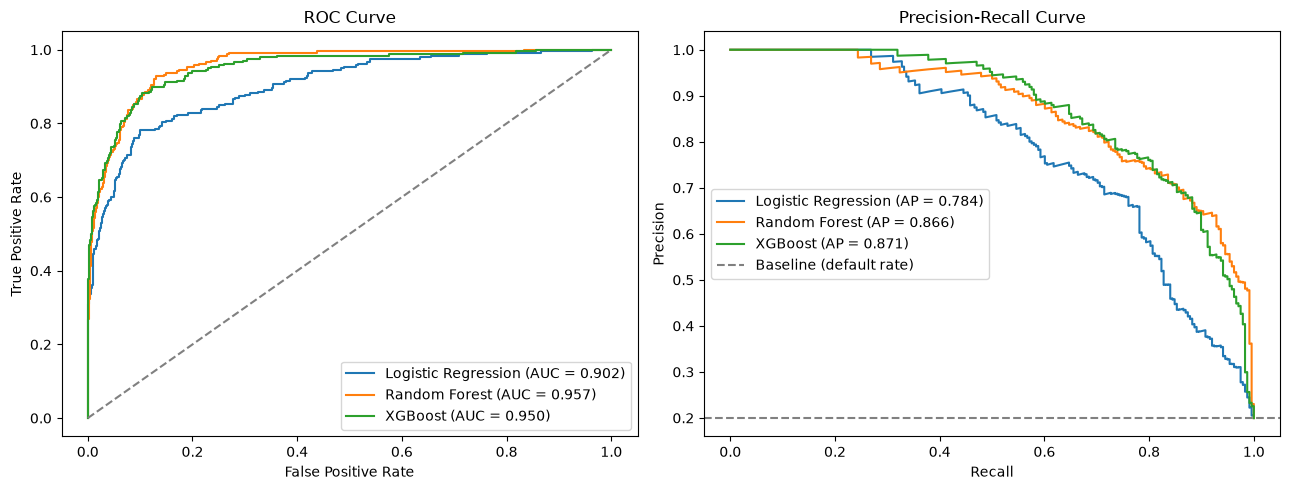

In [8]:
# Plot the ROC and Precision-Recall curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, prob in test_probabilities.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, prob):.3f})")

    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[1].plot(recall, precision, label=f"{name} (AP = {average_precision_score(y_test, prob):.3f})")

axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey')
axes[0].set_title('ROC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend()

axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label='Baseline (default rate)')
axes[1].set_title('Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend()

plt.tight_layout()
plt.show()

The results on the test set are consistent with the cross-validation results, so the models are not overfitting the training data.

With a Gini of around 0.90, the XGBoost model has a very high discriminatory power. In real credit scoring a Gini between 0.4 and 0.7 is common, so this result is probably helped by the characteristics of this dataset (for example, the strong signal of the missing `DEBTINC` values) and should not be expected with real bank data.

## 5.6 Calibration

A model can rank clients correctly (high AUC) but still give wrong probabilities. For example, it could predict 40% for a group of clients that really defaults 20% of the time.

The calibration curve groups the clients by predicted probability and compares it with the real default rate of each group. A perfectly calibrated model follows the diagonal.

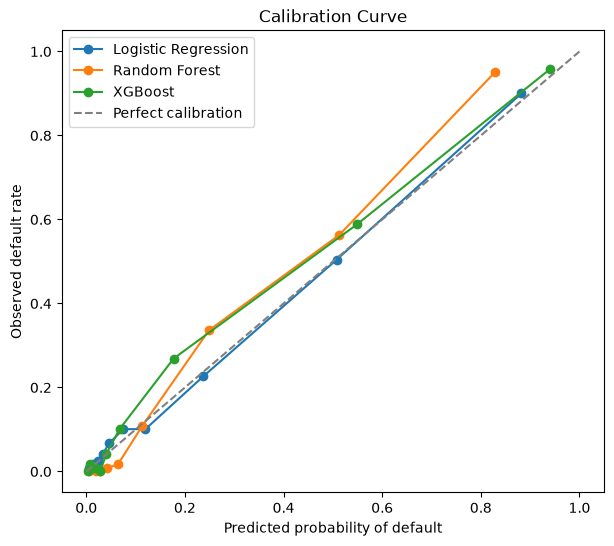

In [9]:
# Plot the calibration curve of each model
plt.figure(figsize=(7, 6))

for name, prob in test_probabilities.items():
    observed, predicted = calibration_curve(y_test, prob, n_bins=10, strategy='quantile')
    plt.plot(predicted, observed, marker='o', label=name)

plt.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Perfect calibration')
plt.title('Calibration Curve')
plt.xlabel('Predicted probability of default')
plt.ylabel('Observed default rate')
plt.legend()
plt.show()

XGBoost follows the diagonal reasonably well, so its probabilities can be used to calculate the expected loss. It slightly **underestimates** the risk in the middle range (predicted PD between ~5% and ~50%), which should be taken into account in the credit policy. A calibration step (for example, isotonic regression) could correct it, but it is not applied to keep the project simple.

## 5.7 Out-of-fold predictions and model saving

To choose the approval threshold in the next notebook without using the test set, the out-of-fold predictions of the training set are calculated. Each client of the training set receives a probability from a model that was not trained with that client.

In [10]:
# Select the final model
final_model = models['XGBoost']

# Out-of-fold predictions for the training set (used to choose the threshold)
oof_prob = cross_val_predict(final_model, X_train, y_train, cv=cv, method='predict_proba')[:, 1]

train_scores = X_train[['LOAN']].copy()
train_scores['BAD'] = y_train
train_scores['PD'] = oof_prob

# Predictions for the test set (used to evaluate the credit policy)
test_scores = X_test[['LOAN']].copy()
test_scores['BAD'] = y_test
test_scores['PD'] = test_probabilities['XGBoost']

train_scores.to_csv('../data/train_scores.csv', index=False)
test_scores.to_csv('../data/test_scores.csv', index=False)

In [11]:
# Save the final model and the test set
joblib.dump(final_model, '../models/xgboost_credit_risk_model.pkl')
X_test.to_csv('../data/X_test.csv', index=False)

## Modeling Conclusions

- Three models were compared using 5-fold stratified cross-validation: Logistic Regression, Random Forest and XGBoost.
- Accuracy was not used due to the class imbalance. The models were evaluated with ROC-AUC, Gini, PR-AUC, KS and Brier score.
- The tree-based models clearly outperformed Logistic Regression, confirming the non-linear relationships observed in the EDA.
- **XGBoost** was selected as the final model, with a test ROC-AUC of ~0.95 (Gini ~0.90) and a reasonable calibration (with a slight underestimation of risk in the middle range).
- The very high performance is probably related to the characteristics of this dataset and should be interpreted with caution.

The next notebook uses the predicted probabilities to design a credit approval policy and to explain the model decisions.